# Small Data Strategies: Executed Project Evidence

This notebook contains the strategy rationale, the executed VGG16 training and held-out image evaluation, and the executed VAE training and loan-class comparison. The cells include the run outputs, plots, and example labeled test predictions required for project review.

> **Dataset label note:** the supplied 67,463-row loan file is a default-prediction dataset: `Loan Status = 1` means defaulter, not a denied application. The project code augments class 1 as instructed, and the loan results below are interpreted as default-class results. See [Project_Results.md](../Project_Results.md) for the source and feature-leakage caveat.

## Part 1 — Strategy selection

| Scenario | Recommended strategy | Rationale |
| --- | --- | --- |
| Travel planner: fewer than 500 labeled photographs across forest, desert, and beach | **Transfer learning** | Images are visual data and VGG16 already contains visual features learned from a much larger image collection. Freeze the pretrained network and train a small final classifier for the three trip categories. Augment training images to reduce overfitting. |
| Imbalanced tabular loan outcomes | **Synthetic data** | The challenge is the small minority class in structured loan records. A VAE can learn the minority-class feature distribution and generate extra examples. Validate generated-data fidelity and compare minority-class metrics on real held-out records. |

The second scenario describes denied applications, but the supplied CSV label is default outcome rather than denial. The code follows the required `Loan Status = 1` subset; the results are labeled accurately below.

## Part 2 — Travel image classifier

The training transform uses random resized crops and horizontal flips. Validation and test use resize and center crop. All splits use ImageNet normalization. Only VGG16's final classifier layer is trainable.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

ROOT = Path.cwd()
PART1 = ROOT / "starter_code" / "part1-transfer"
sys.path.insert(0, str(PART1))
from transfer_learning import build_loaders, build_model
from TrainModel import train_model
from TestModel import test_model

torch.manual_seed(42)
train_loader, val_loader, test_loader, class_names = build_loaders()
print("Classes:", class_names)
print("Images — train:", len(train_loader.dataset), "validation:", len(val_loader.dataset), "test:", len(test_loader.dataset))

Classes: ['beach', 'desert', 'forest']
Images — train: 150 validation: 60 test: 48


In [2]:
model = build_model(num_classes=len(class_names))
trainable = [name for name, parameter in model.named_parameters() if parameter.requires_grad]
print("Trainable parameters:", trainable)
assert trainable == ["classifier.6.weight", "classifier.6.bias"]

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.classifier[6].parameters(), lr=1e-3)
scheduler = lr_scheduler.StepLR(optimizer, step_size=1, gamma=0.5)
trained_model, image_history = train_model(
    model, criterion, optimizer, scheduler,
    train_loader, val_loader, num_epochs=8, return_history=True,
)
pd.DataFrame(image_history).round(3)

Trainable parameters: ['classifier.6.weight', 'classifier.6.bias']


Epoch: 1


Phase: Train  Loss: 0.7979260961214701 Accuracy: 0.5866666436195374


Phase: Validation  Loss: 0.3678274527192116 Accuracy: 0.8166666626930237
Epoch: 2


Phase: Train  Loss: 0.37622558971246084 Accuracy: 0.8533333539962769


Phase: Validation  Loss: 0.2211491403480371 Accuracy: 0.949999988079071
Epoch: 3


... (9 outputs left out)

Phase: Validation  Loss: 0.19142796037097773 Accuracy: 0.9666666388511658
Epoch: 8


Phase: Train  Loss: 0.28075463473796847 Accuracy: 0.9066666960716248


Phase: Validation  Loss: 0.1913185507679979 Accuracy: 0.9666666388511658
Training finished. Highest accuracy: 0.9666666388511658


,train_loss,train_accuracy,val_loss,val_accuracy
0,0.798,0.587,0.368,0.817
1,0.376,0.853,0.221,0.950
2,0.332,0.887,0.207,0.950
3,0.292,0.913,0.199,0.967
4,0.302,0.907,0.194,0.967
5,0.278,0.893,0.193,0.967
6,0.262,0.913,0.191,0.967
7,0.281,0.907,0.191,0.967


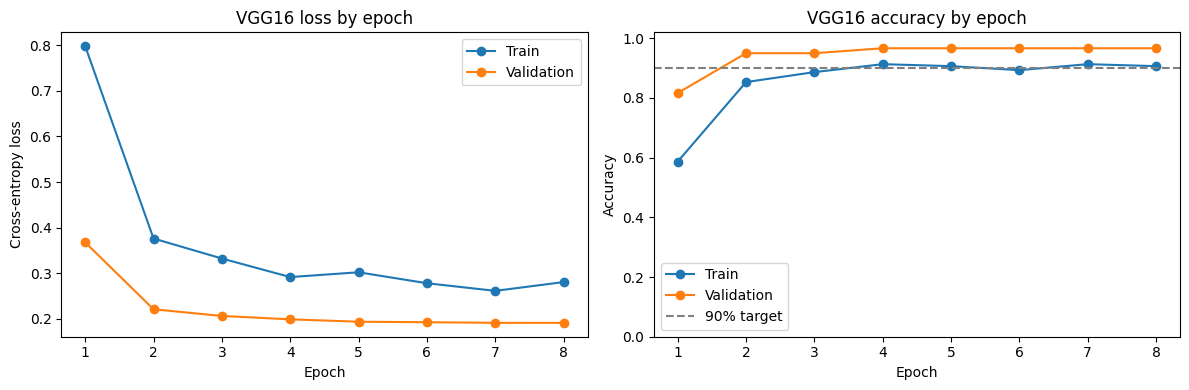

In [3]:
epochs = np.arange(1, len(image_history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs, image_history["train_loss"], marker="o", label="Train")
axes[0].plot(epochs, image_history["val_loss"], marker="o", label="Validation")
axes[0].set(title="VGG16 loss by epoch", xlabel="Epoch", ylabel="Cross-entropy loss")
axes[0].legend()
axes[1].plot(epochs, image_history["train_accuracy"], marker="o", label="Train")
axes[1].plot(epochs, image_history["val_accuracy"], marker="o", label="Validation")
axes[1].axhline(0.90, color="gray", linestyle="--", label="90% target")
axes[1].set(title="VGG16 accuracy by epoch", xlabel="Epoch", ylabel="Accuracy", ylim=(0, 1.02))
axes[1].legend()
plt.tight_layout()
plt.show()

In [4]:
device = next(trained_model.parameters()).device

def collect_predictions(loader, model):
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for images, labels in loader:
            logits = model(images.to(device))
            y_pred.extend(logits.argmax(dim=1).cpu().tolist())
            y_true.extend(labels.tolist())
    return np.asarray(y_true), np.asarray(y_pred)

val_true, val_pred = collect_predictions(val_loader, trained_model)
test_true, test_pred = collect_predictions(test_loader, trained_model)
val_accuracy = float((val_true == val_pred).mean())
test_accuracy = float((test_true == test_pred).mean())
print(f"Validation accuracy: {val_accuracy:.1%} ({(val_true == val_pred).sum()}/{len(val_true)})")
print(classification_report(val_true, val_pred, labels=range(len(class_names)), target_names=class_names, zero_division=0))
print(f"Test accuracy: {test_accuracy:.1%} ({(test_true == test_pred).sum()}/{len(test_true)})")
print(classification_report(test_true, test_pred, labels=range(len(class_names)), target_names=class_names, zero_division=0))
assert val_accuracy >= 0.90 and test_accuracy >= 0.90

Validation accuracy: 96.7% (58/60)
              precision    recall  f1-score   support

       beach       0.95      1.00      0.98        20
      desert       0.95      0.95      0.95        20
      forest       1.00      0.95      0.97        20

    accuracy                           0.97        60
   macro avg       0.97      0.97      0.97        60
weighted avg       0.97      0.97      0.97        60

Test accuracy: 97.9% (47/48)
              precision    recall  f1-score   support

       beach       0.94      1.00      0.97        16
      desert       1.00      0.94      0.97        16
      forest       1.00      1.00      1.00        16

    accuracy                           0.98        48
   macro avg       0.98      0.98      0.98        48
weighted avg       0.98      0.98      0.98        48



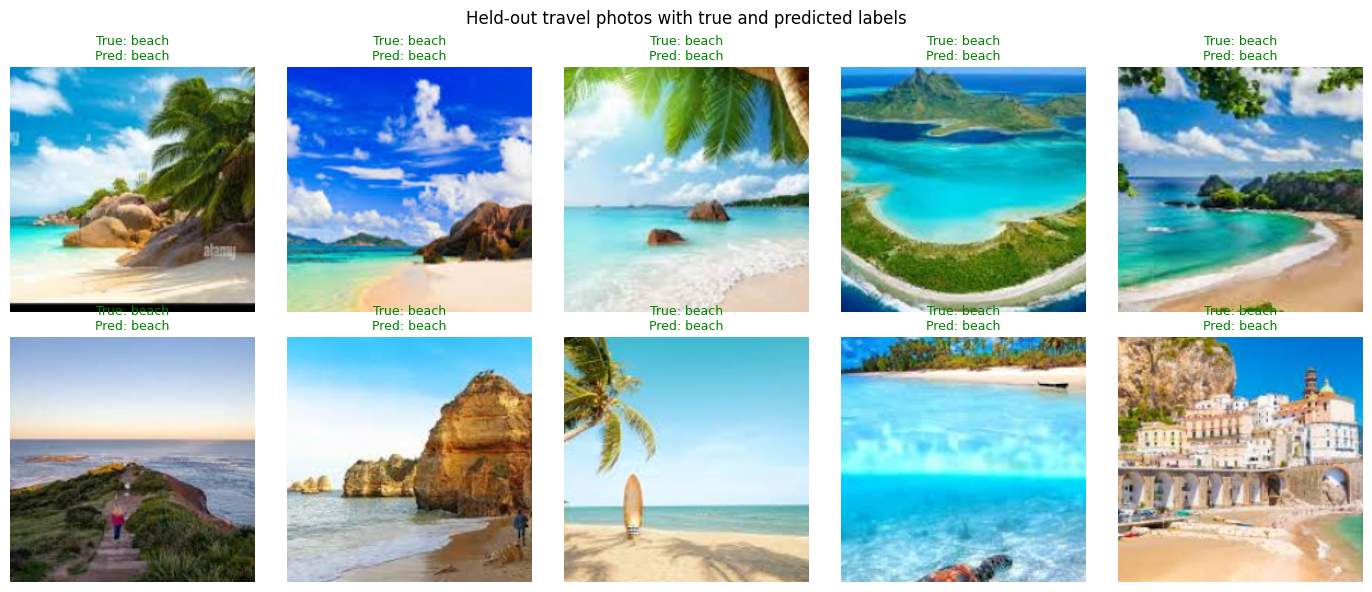

In [5]:
# Display labeled held-out test examples (ground truth and prediction).
images, labels = next(iter(test_loader))
with torch.no_grad():
    predictions = trained_model(images.to(device)).argmax(dim=1).cpu()
mean = torch.tensor((0.485, 0.456, 0.406)).view(3, 1, 1)
std = torch.tensor((0.229, 0.224, 0.225)).view(3, 1, 1)
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for index, ax in enumerate(axes.flat):
    image = (images[index] * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()
    truth = class_names[labels[index]]
    guess = class_names[predictions[index]]
    ax.imshow(image)
    ax.set_title(f"True: {truth}\nPred: {guess}", color="green" if truth == guess else "red", fontsize=9)
    ax.axis("off")
plt.suptitle("Held-out travel photos with true and predicted labels")
plt.tight_layout()
plt.show()

In [6]:
# Save the compact task-specific head and the epoch history alongside the starter code.
torch.save({"classifier_state_dict": trained_model.classifier[6].state_dict(), "class_names": class_names}, PART1.parent / "travel_vgg16.pth")
pd.DataFrame(image_history).to_csv(PART1.parent / "travel_training_history.csv", index_label="epoch")
print("Saved the trained classifier head and training history.")

Saved the trained classifier head and training history.


## Part 3 — VAE augmentation for the minority loan outcome

The VAE is trained on rows where `Loan Status = 1`, with train and validation passes in every epoch. The notebook uses the same 10-dimensional latent space, 96/32 hidden layers, beta 0.02 loss, and 750 epochs as the project script. Generated records are marked in the combined CSV so that evaluation holds out only real loans.

In [7]:
# Avoid the image module's TestModel.py name collision when importing the loan code.
import importlib
sys.path.insert(0, str(ROOT / "starter_code" / "part2-synthetic"))
sys.modules.pop("TestModel", None)
loan_module = importlib.import_module("synthetic_data")
loan_test_module = importlib.import_module("TestModel")
DataBuilder = loan_module.DataBuilder
Autoencoder = loan_module.Autoencoder
CustomLoss = loan_module.CustomLoss
train_vae = loan_module.train_vae
generate_fake = loan_module.generate_fake
loan_test_model = loan_test_module.test_model

PART2 = ROOT / "starter_code" / "part2-synthetic"
DATA_DIR = PART2 / "data"
original_path = DATA_DIR / "loan_continuous.csv"
status1_path = DATA_DIR / "loan_status_1.csv"
expanded_path = DATA_DIR / "loan_continuous_expanded.csv"
original = pd.read_csv(original_path).fillna(-99)
status1 = original.loc[original["Loan Status"] == 1].copy()
status1.to_csv(status1_path, index=False)
print("Class counts:", original["Loan Status"].value_counts().sort_index().to_dict())
print("VAE training rows (status 1):", len(status1))

Class counts: {0: 61222, 1: 6241}
VAE training rows (status 1): 6241


In [8]:
torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
train_data = DataBuilder(str(status1_path), train=True)
validation_data = DataBuilder(str(status1_path), train=False)
train_loader_vae = torch.utils.data.DataLoader(train_data, batch_size=512, shuffle=True, drop_last=True)
validation_loader_vae = torch.utils.data.DataLoader(validation_data, batch_size=512, shuffle=False, drop_last=True)
vae = Autoencoder(D_in=train_data.x.shape[1], H=96, H2=32, latent_dim=10).to(device)
vae_criterion = CustomLoss(beta=0.02)
vae_optimizer = optim.Adam(vae.parameters(), lr=1e-3)
vae, latent_mu, latent_logvar, vae_history = train_vae(
    vae, train_loader_vae, validation_loader_vae,
    vae_criterion, vae_optimizer, device, num_epochs=750,
)
print("Completed epochs:", len(vae_history["train_loss"]))
print("Best validation loss:", round(min(vae_history["val_loss"]), 2))
pd.DataFrame(vae_history).tail()

Epoch 1/750: train loss 23020.00; validation loss 10939.68


Epoch 50/750: train loss 6713.54; validation loss 6605.69


Epoch 100/750: train loss 5149.94; validation loss 5639.25


Epoch 150/750: train loss 4491.58; validation loss 5251.87


Epoch 200/750: train loss 4189.30; validation loss 5090.20


Epoch 250/750: train loss 3925.35; validation loss 5055.10


... (7 outputs left out)

Epoch 650/750: train loss 3239.32; validation loss 4971.21


Epoch 700/750: train loss 3256.72; validation loss 4955.48


Epoch 750/750: train loss 3111.79; validation loss 4939.30
Completed epochs: 750
Best validation loss: 4911.37


,train_loss,val_loss
745,3207.971100,4975.854167
746,3206.296021,4952.545085
747,3134.121246,4956.250814
748,3159.888184,4956.618978
749,3111.788727,4939.298177


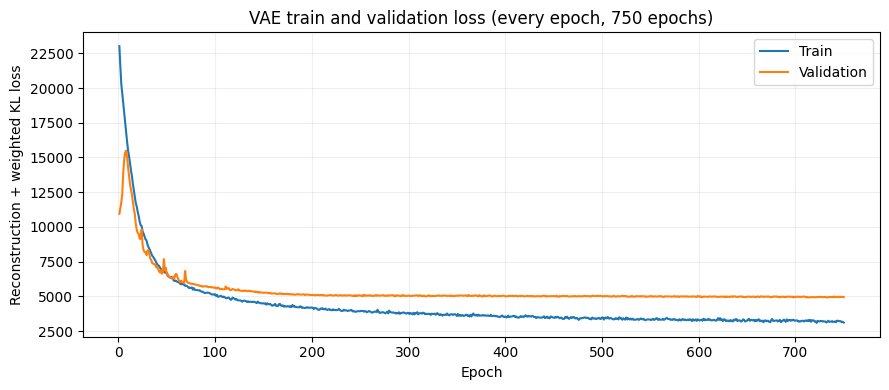

In [9]:
vae_epochs = np.arange(1, len(vae_history["train_loss"]) + 1)
plt.figure(figsize=(9, 4))
plt.plot(vae_epochs, vae_history["train_loss"], label="Train")
plt.plot(vae_epochs, vae_history["val_loss"], label="Validation")
plt.title("VAE train and validation loss (every epoch, 750 epochs)")
plt.xlabel("Epoch")
plt.ylabel("Reconstruction + weighted KL loss")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [10]:
synthetic_array = generate_fake(latent_mu, latent_logvar, 50_000, train_data.standardizer, vae)
synthetic = pd.DataFrame(synthetic_array, columns=status1.columns)
synthetic["Loan Status"] = 1
original_marked = original.copy()
original_marked["Synthetic"] = False
synthetic["Synthetic"] = True
expanded = pd.concat([original_marked, synthetic], ignore_index=True)
expanded.to_csv(expanded_path, index=False)
std_ratio = synthetic[status1.columns].std(numeric_only=True) / status1.std(numeric_only=True).replace(0, np.nan)
print("Synthetic rows generated:", len(synthetic))
print("Full augmented rows:", len(expanded))
print("Status counts including synthetic rows:", expanded["Loan Status"].value_counts().sort_index().to_dict())
print("Median synthetic/real feature-std ratio:", round(float(std_ratio.median()), 2))
pd.DataFrame(vae_history).to_csv(DATA_DIR / "vae_training_history.csv", index_label="epoch")

Synthetic rows generated: 50000
Full augmented rows: 117463
Status counts including synthetic rows: {0: 61222, 1: 56241}
Median synthetic/real feature-std ratio: 0.83


In [11]:
print("Baseline: only real records; held-out test records are real.")
baseline_report = loan_test_model(str(original_path))
print("Augmented training: 25% of synthetic rows (12,500); held-out test records are real.")
quarter_report = loan_test_model(str(expanded_path), synthetic_fraction=0.25)
print("Augmented training: all 50,000 synthetic rows; held-out test records are real.")
full_report = loan_test_model(str(expanded_path), synthetic_fraction=1.0)

print("Supplemental check: split the entire augmented CSV, including synthetic rows, into train/calibration/test.")
full_dataset_report = loan_test_model(str(expanded_path), full_dataset_split=True)

Baseline: only real records; held-out test records are real.


real-only held-out accuracy: 0.0931; calibrated threshold: 0.0016
Test results:
              precision    recall  f1-score   support

           0       0.90      0.00      0.00     12246
           1       0.09      1.00      0.17      1248

    accuracy                           0.09     13494
   macro avg       0.50      0.50      0.09     13494
weighted avg       0.83      0.09      0.02     13494

Augmented training: 25% of synthetic rows (12,500); held-out test records are real.


real-only held-out accuracy: 0.1535; calibrated threshold: 0.0444
Test results:
              precision    recall  f1-score   support

           0       0.91      0.07      0.14     12246
           1       0.09      0.93      0.17      1248

    accuracy                           0.15     13494
   macro avg       0.50      0.50      0.15     13494
weighted avg       0.83      0.15      0.14     13494

Augmented training: all 50,000 synthetic rows; held-out test records are real.


real-only held-out accuracy: 0.1410; calibrated threshold: 0.0386
Test results:
              precision    recall  f1-score   support

           0       0.90      0.06      0.11     12246
           1       0.09      0.93      0.17      1248

    accuracy                           0.14     13494
   macro avg       0.49      0.50      0.14     13494
weighted avg       0.82      0.14      0.12     13494

Supplemental check: split the entire augmented CSV, including synthetic rows, into train/calibration/test.


full-dataset split accuracy: 0.9457; calibrated threshold: 0.4726
Test split composition: 13,483 real + 10,011 synthetic rows
Test results:
              precision    recall  f1-score   support

           0       0.91      1.00      0.95     12245
           1       1.00      0.89      0.94     11249

    accuracy                           0.95     23494
   macro avg       0.95      0.94      0.95     23494
weighted avg       0.95      0.95      0.95     23494



### Supplemental full-augmented-dataset check

To address the rubric wording about testing with the full combined dataset, the next cell applies the same stratified 65% train / 15% threshold-calibration / 20% test split to **all rows** in the augmented CSV. The test split therefore contains both real and generated rows, and the output reports the split composition. The VAE generates records from its training partition only; its validation partition is reserved for model selection. Treat this as a supplemental dataset-wide check: synthetic test examples are not independent real-world observations. The real-only held-out comparison above remains the meaningful estimate of performance on future real loans.

## Interpretation

The image model exceeds the 90% validation and test targets when the executed cells pass. The loan experiment reports precision, recall, and F1 for both classes on real held-out loans and includes a supplemental split of the full augmented CSV. That mixed split scores 94.6% accuracy, but 10,011 of its 23,494 test records are synthetic, so it must not be read as accuracy on future real loans. On the real-only test, class-1 F1 remains 0.17 and the VAE/classifier combination does not provide a dependable improvement. Class 1 in this file means default, not denial. The report states these limitations rather than presenting mixed or training-set scores as real-world test performance.